# 05 - Model Evaluation, Thresholds and Business Costs

**Goal:** judge the final model honestly: with the right metrics, with uncertainty, and with a decision threshold chosen for a *business objective* rather than by habit.

## Metrics: what each one answers
| Metric | Question it answers | Watch out for |
|---|---|---|
| **Accuracy** | What fraction of predictions are right? | Misleading with imbalance: "always stays" scores 73.5% here. |
| **Precision** | Of customers we flag, how many really churn? | Ignores churners we missed. |
| **Recall** | Of customers who churn, how many do we flag? | Ignores false alarms; flagging everyone gives recall 1.0. |
| **F1** | Harmonic mean of precision and recall | Treats a false alarm and a miss as equally bad, which is rarely true in business. |
| **ROC-AUC** | If I pick a random churner and a random stayer, how often does the churner get the higher score? | Threshold-free *ranking* quality; optimistic with heavy imbalance because true negatives dominate the false-positive rate. |
| **PR-AUC (average precision)** | Precision averaged over all recall levels | No-skill = prevalence (0.265), so it is more informative than accuracy/ROC when the positive class is the one we care about. |
| **Brier score** | Mean squared error of the probabilities | Measures probability quality (lower is better; the "always 26.5%" baseline scores 0.195). |

**Business meaning of errors.** A **false positive** = we spend retention budget (and perhaps annoy or discount) on someone who would have stayed. A **false negative** = a churner we never contacted: lost revenue. **Precision and recall conflict** because lowering the threshold flags more customers (catches more churners, recall up; but more of those flagged are stayers, precision down).

**Calibration** asks whether "30% risk" really means ~30% of such customers churn. It matters because we will multiply probabilities by dollar values; an uncalibrated score gives wrong expected costs.

## Part 1 - Development-set evidence (out-of-fold predictions)
Every development customer has a prediction from a model that never saw them (5-fold out-of-fold). We use these to study thresholds, *not* the test set.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))                       # lets notebooks import the src/ package

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src import config

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 170)
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)

def savefig(name):
    """Save the current figure into reports/figures (used by README and dashboard)."""
    plt.savefig(config.FIGURES_DIR / name, dpi=150, bbox_inches="tight")

In [2]:
import json, joblib
from src import evaluate as ev
from src.config import CostAssumptions
meta = json.loads(config.METADATA_PATH.read_text())
oof = pd.read_csv(config.OOF_PATH)                       # out-of-fold probabilities for the development set
y_oof, p_oof = oof["churn"].to_numpy(), oof["oof_probability"].to_numpy()
costs = CostAssumptions(**meta["cost_assumptions"]); chosen_t = meta["threshold"]
print(f"Final model: {meta['model_name']} | chosen threshold: {chosen_t:.2f} | out-of-fold customers: {len(y_oof)}")

Final model: LightGBM | chosen threshold: 0.22 | out-of-fold customers: 5634


,accuracy,precision,recall,f1,flagged_fraction,roc_auc,average_precision,brier,tp,fp,tn,fn
threshold 0.50,0.808,0.671,0.543,0.600,0.215,0.849,0.67,0.133,812.0,399.0,3740.0,683.0
threshold 0.22,0.732,0.497,0.845,0.626,0.451,0.849,0.67,0.133,1264.0,1279.0,2860.0,231.0


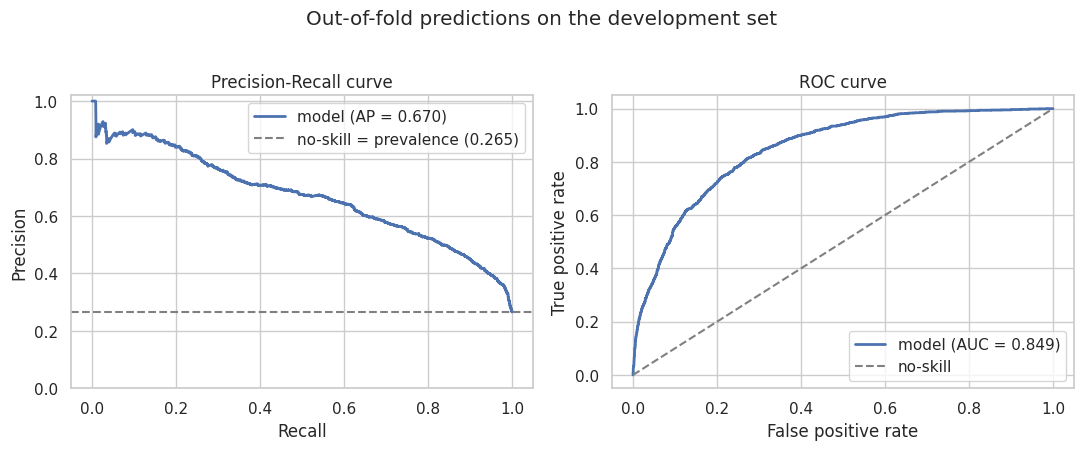

In [3]:
rows = {f"threshold {t:.2f}": ev.compute_metrics(y_oof, p_oof, t) for t in [0.5, chosen_t]}
tbl = pd.DataFrame(rows).T[["accuracy", "precision", "recall", "f1", "flagged_fraction", "roc_auc", "average_precision", "brier", "tp", "fp", "tn", "fn"]]
display(tbl.round(3))
ev.plot_pr_roc(y_oof, p_oof, "Out-of-fold predictions on the development set", "oof_pr_roc_curves.png"); plt.show()

**Reading it.** At the default 0.5 threshold the model has accuracy 0.81, precision 0.67 but recall only 0.54: it misses almost half of churners. At the lower threshold (0.22) recall rises to 0.85 while precision falls to 0.50 and accuracy *drops* to 0.73. **A "worse" accuracy can be the better business decision** - accuracy is not the right objective here. The ROC/PR curves do not depend on the threshold: they show the ranking quality (ROC-AUC 0.85; PR-AUC 0.67 vs a no-skill 0.265).

### Calibration

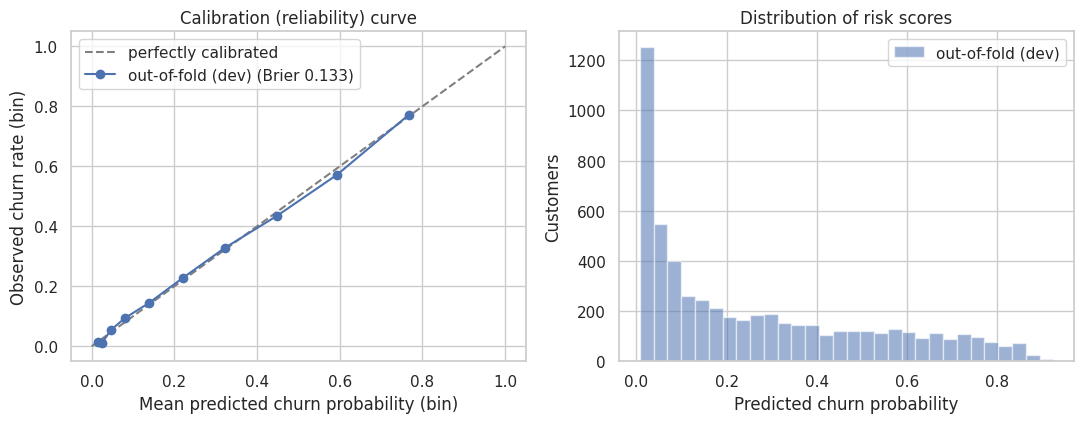

,0,1,2,3,4,5,6,7,8,9
mean_predicted_probability,0.014,0.026,0.046,0.080,0.138,0.222,0.322,0.448,0.593,0.767
observed_churn_rate,0.014,0.012,0.053,0.094,0.144,0.229,0.328,0.435,0.572,0.771


In [4]:
ev.plot_calibration({"out-of-fold (dev)": (y_oof, p_oof)}, "oof_calibration_curve.png"); plt.show()
display(ev.calibration_table(y_oof, p_oof).round(3).T)

**Reading it.** Bins sit close to the diagonal: when the model says ~45% the observed churn rate is ~44%, at ~77% it is ~77%. The model is reasonably well calibrated *without* any recalibration step, which is what makes the cost calculation below meaningful. (Caveat: calibration was checked on out-of-fold data from the same dataset; calibration can degrade under drift, so a real deployment should monitor it. The lowest bins have small counts, so small deviations there are noise.)

## Part 2 - The threshold is a decision, not a model property
For each candidate threshold we flag customers with probability >= threshold.

,threshold,flagged_pct,precision,recall,f1,tp,fp,tn,fn
0,0.10,60.845,0.409,0.937,0.569,1401,2027,2112,94
1,0.15,53.230,0.449,0.900,0.599,1346,1653,2486,149
2,0.20,47.018,0.484,0.858,0.619,1282,1367,2772,213
3,0.22,45.137,0.497,0.845,0.626,1264,1279,2860,231
4,0.30,37.025,0.544,0.759,0.634,1135,951,3188,360
5,0.40,28.239,0.605,0.644,0.624,963,628,3511,532
6,0.50,21.494,0.671,0.543,0.600,812,399,3740,683
7,0.60,14.466,0.710,0.387,0.501,579,236,3903,916
8,0.70,8.502,0.800,0.256,0.388,383,96,4043,1112


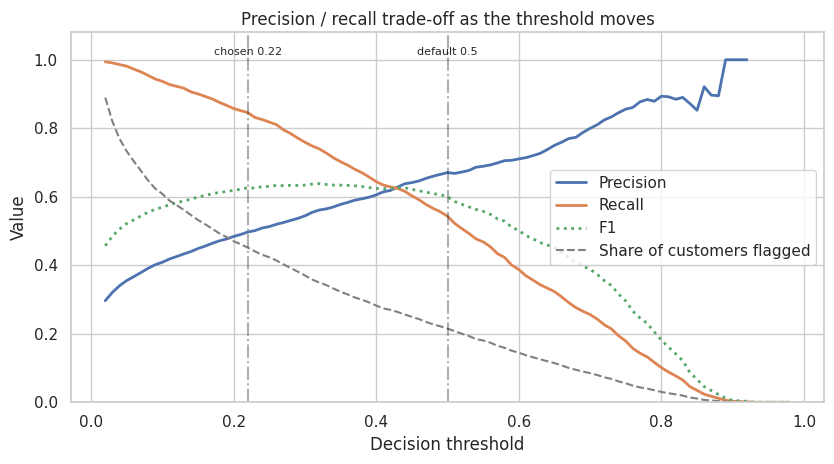

ROC-AUC / PR-AUC at every threshold (identical): {0.1: (0.8491, 0.6698), 0.3: (0.8491, 0.6698), 0.5: (0.8491, 0.6698), 0.7: (0.8491, 0.6698)}


In [5]:
grid = [0.10, 0.15, 0.20, 0.22, 0.30, 0.40, 0.50, 0.60, 0.70]
tt = ev.threshold_table(y_oof, p_oof, grid)
display(tt.round(3))
ev.plot_threshold_pr(ev.threshold_table(y_oof, p_oof), {f"chosen {chosen_t:.2f}": chosen_t, "default 0.5": 0.5}, "threshold_precision_recall_oof.png"); plt.show()
# the model's RANKING is untouched by the threshold:
print("ROC-AUC / PR-AUC at every threshold (identical):", {round(t, 2): (round(ev.compute_metrics(y_oof, p_oof, t)["roc_auc"], 4), round(ev.compute_metrics(y_oof, p_oof, t)["average_precision"], 4)) for t in [0.1, 0.3, 0.5, 0.7]})

**Reading it.** Lowering the threshold from 0.5 to 0.2 raises the share of customers flagged from ~21% to ~47%, recall from 0.54 to 0.86, and lowers precision from 0.67 to 0.48. F1 peaks around 0.3 - but F1 weighs the two error types equally, which is an assumption nobody has justified. The last printed line confirms: **ROC-AUC and PR-AUC are identical at every threshold**. Thresholding changes decisions, not the model's ranking of customers; it cannot "improve" the model.

## Part 3 - Cost-based threshold (ILLUSTRATIVE numbers!)
> **Everything in this section depends on assumed costs, not measurements from the dataset.** The dataset contains no information about what a retention offer costs or how often it works.

**Assumptions (labelled, adjustable):** a retained would-be churner is worth **V = $400**; each retention action costs **C = $25** (paid for every flagged customer); an action succeeds with probability **s = 30%**.

**Expected cost of a threshold**  = `FN x V` (missed churners are lost) `+ TP x (C + (1-s) x V)` (we pay C and with prob. 1-s still lose them) `+ FP x C` (wasted action).

**A useful shortcut.** Flagging customer *i* is worth it when `p_i x s x V > C`, i.e. when `p_i > C / (s x V)`. With the numbers above that is 25 / (0.3 x 400) = **0.208**. This holds *if probabilities are calibrated* - another reason calibration matters. We do not rely on it: we search for the best threshold empirically on out-of-fold data and check that the two agree.

ILLUSTRATIVE assumptions (NOT measured from the data): {'customer_value': 400.0, 'intervention_cost': 25.0, 'intervention_success': 0.3}
Calibrated-theory break-even threshold  C/(s*V) = 0.208
Empirical cost-optimal threshold on out-of-fold data = 0.22  (stored in metadata: 0.22)
{'no_action': '$598,000', 'flag_everyone': '$559,450'} <- expected cost of 'do nothing' and 'contact everyone'


,threshold,flagged_pct,tp,fp,fn,expected_total_cost,net_savings_vs_no_action,net_savings_per_1000
8,0.1,60.8,1401,2027,94,515580.0,82420.0,14629.0
13,0.2,53.2,1346,1653,149,511455.0,86545.0,15361.2
18,0.2,47.0,1282,1367,213,510385.0,87615.0,15551.1
20,0.2,45.1,1264,1279,231,509895.0,88105.0,15638.1
28,0.3,37.0,1135,951,360,513950.0,84050.0,14918.4
38,0.4,28.2,963,628,532,522215.0,75785.0,13451.4
48,0.5,21.5,812,399,683,530835.0,67165.0,11921.4
58,0.6,14.5,579,236,916,548895.0,49105.0,8715.8
68,0.7,8.5,383,96,1112,564015.0,33985.0,6032.1


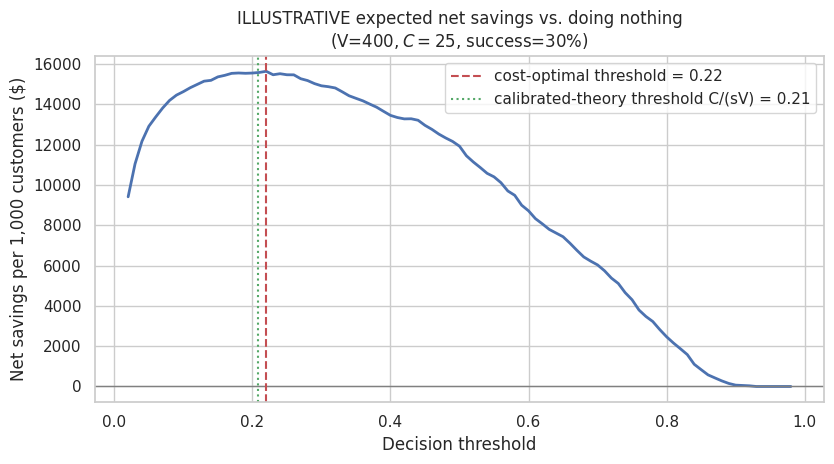

In [6]:
print("ILLUSTRATIVE assumptions (NOT measured from the data):", costs.as_dict())
print(f"Calibrated-theory break-even threshold  C/(s*V) = {ev.theoretical_threshold(costs):.3f}")
best_t, ctab = ev.choose_threshold_by_cost(y_oof, p_oof, costs)
print(f"Empirical cost-optimal threshold on out-of-fold data = {best_t:.2f}  (stored in metadata: {chosen_t:.2f})")
base = ev.baseline_costs(y_oof, costs); print({k: f"${v:,.0f}" for k, v in base.items()}, "<- expected cost of 'do nothing' and 'contact everyone'")
show = ctab[ctab.threshold.isin(grid)][["threshold", "flagged_pct", "tp", "fp", "fn", "expected_total_cost", "net_savings_vs_no_action", "net_savings_per_1000"]]
display(show.round(1))
ev.plot_cost_curve(ctab, costs, chosen_t, "threshold_cost_curve_oof.png"); plt.show()

**Reading it.** The empirical optimum (0.22) is almost exactly the theoretical break-even (0.21), which is a good consistency check on both the calibration and the code. The curve is **flat near its optimum** (thresholds from roughly 0.15 to 0.26 are within ~2%), so we should not over-read the exact value. At the optimum, the framework's expected net savings are about $15,600 per 1,000 customers *under these assumptions*, versus about $11,900 at the default 0.5 threshold and roughly $6,800 per 1,000 for contacting everyone (the test-set equivalents are in `reports/model_evaluation.md`). These are model-based expectations, **not** measured retention gains.

### Sensitivity: the "optimal" threshold depends on business inputs

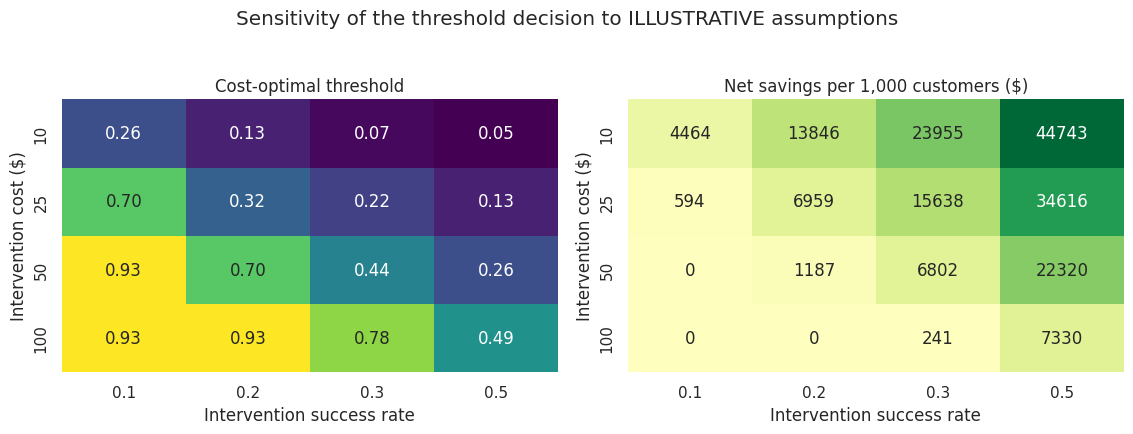

If the team can contact at most 30% of customers, the best feasible threshold is 0.38 -> flags 29.9%, precision 0.594, recall 0.670


In [7]:
best_tab, sav_tab = ev.cost_sensitivity(y_oof, p_oof, intervention_costs=[10, 25, 50, 100], success_rates=[0.10, 0.20, 0.30, 0.50])
ev.plot_sensitivity(best_tab, sav_tab, "threshold_cost_sensitivity.png"); plt.show()
cap_t, _ = ev.choose_threshold_by_cost(y_oof, p_oof, costs, max_flag_fraction=0.30)
capm = ev.compute_metrics(y_oof, p_oof, cap_t)
print(f"If the team can contact at most 30% of customers, the best feasible threshold is {cap_t:.2f} -> flags {capm['flagged_fraction']:.1%}, precision {capm['precision']:.3f}, recall {capm['recall']:.3f}")

**Reading it.** When actions are cheap or very effective the optimal threshold drops (flag almost everyone); when they are expensive or rarely work it rises, and in the corner where an action costs $50-100 but succeeds only 10-20% of the time the best policy is to contact essentially nobody (net savings about $0). Across the grid the optimal threshold ranges from 0.05 to 0.93. So there is **no universally "right" threshold**: it follows from the costs and from operational capacity (a retention team that can contact only 30% of customers must use a higher threshold - about 0.38 here - whatever the break-even says).

### A business-friendly view: risk deciles

In [8]:
d = pd.DataFrame({"p": p_oof, "y": y_oof}).sort_values("p", ascending=False).reset_index(drop=True)
d["decile"] = pd.qcut(d.index, 10, labels=range(1, 11))
dec = d.groupby("decile", observed=True).agg(customers=("y", "size"), churn_rate=("y", "mean"), mean_predicted=("p", "mean")).assign(
    lift=lambda x: x.churn_rate / y_oof.mean())
dec["cum_share_of_churners_captured"] = (d.groupby("decile", observed=True)["y"].sum().cumsum() / d["y"].sum())
display(dec.round(3))

,customers,churn_rate,mean_predicted,lift,cum_share_of_churners_captured
decile,,,,,
1,564,0.771,0.767,2.907,0.291
2,563,0.572,0.593,2.155,0.506
3,563,0.435,0.448,1.640,0.670
4,564,0.328,0.322,1.236,0.794
5,563,0.229,0.222,0.863,0.880
6,563,0.144,0.138,0.542,0.934
7,564,0.094,0.080,0.354,0.970
8,563,0.053,0.046,0.201,0.990
9,563,0.012,0.026,0.047,0.995


**Reading it.** The riskiest 10% of customers churn at ~77% (2.9x the average); the top 30% contain about two-thirds of all churners; the bottom 20% almost never churn (about 1%). This ranking ability - not accuracy - is what makes targeting worthwhile.

## Part 4 - Final held-out test evaluation (done once)
The model, hyper-parameters and threshold were fixed in `python -m src.train` using development data only. We now score the 1,409 test customers. **We will not change anything based on these results.**

,accuracy,precision,recall,f1,flagged_fraction,roc_auc,average_precision,brier,tp,fp,tn,fn
final @ chosen threshold,0.723,0.487,0.832,0.615,0.453,0.849,0.665,0.135,311.0,327.0,708.0,63.0
final @ 0.50,0.801,0.660,0.519,0.581,0.209,0.849,0.665,0.135,194.0,100.0,935.0,180.0
dummy baseline @ 0.50,0.735,0.000,0.000,0.000,0.000,0.500,0.265,0.195,0.0,0.0,1035.0,374.0



95% bootstrap CIs (final model, chosen threshold):
  roc_auc                    0.849   [0.827, 0.870]
  average_precision          0.665   [0.612, 0.713]
  precision                  0.487   [0.448, 0.525]
  recall                     0.832   [0.791, 0.867]
  f1                         0.615   [0.578, 0.646]
  brier                      0.135   [0.124, 0.144]
  net_savings_per_1000   [12,782, 17,424]

Out-of-fold (dev) PR-AUC: 0.67 | test PR-AUC: 0.665


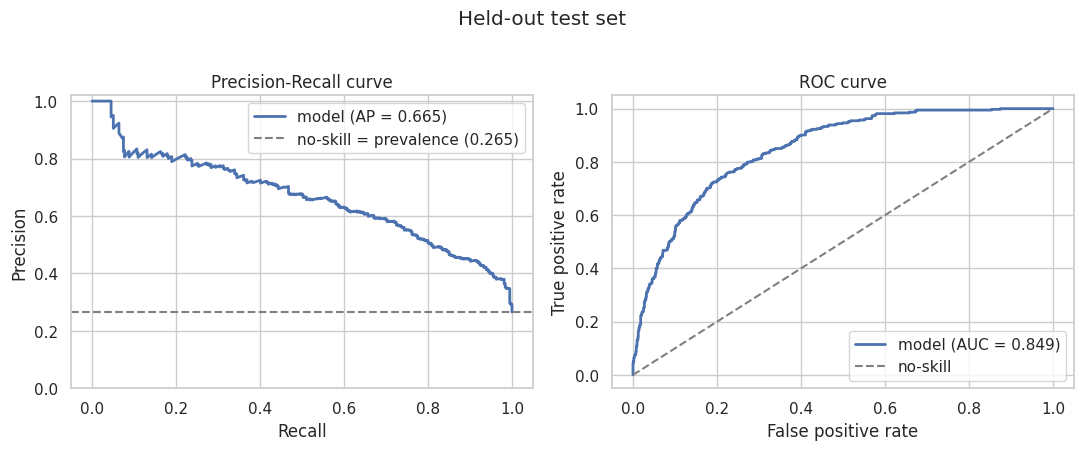

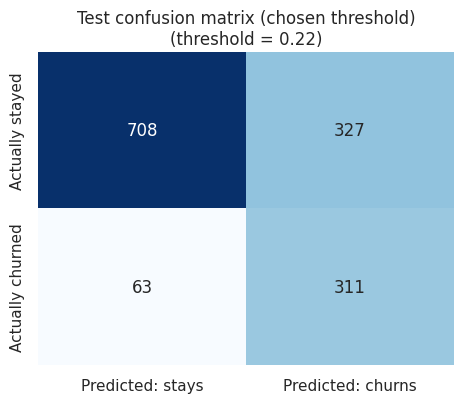

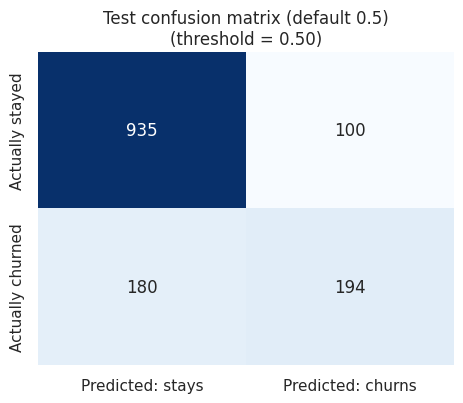

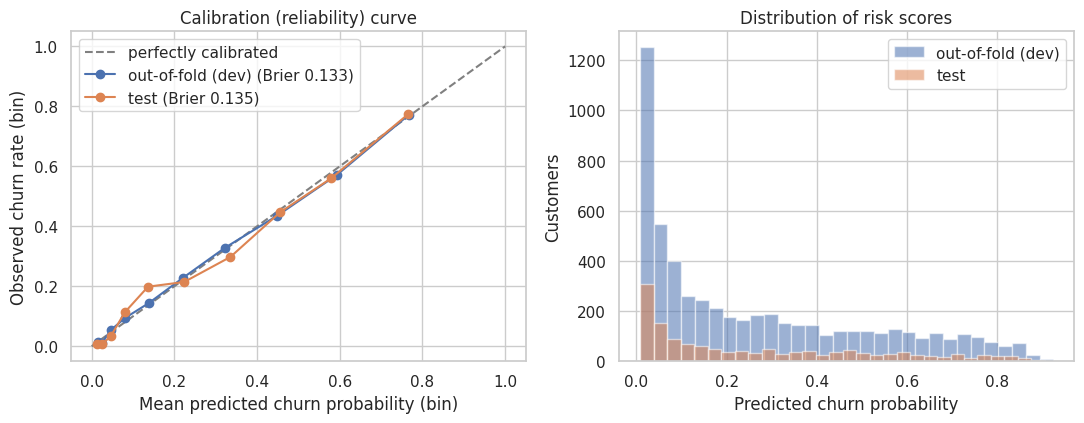

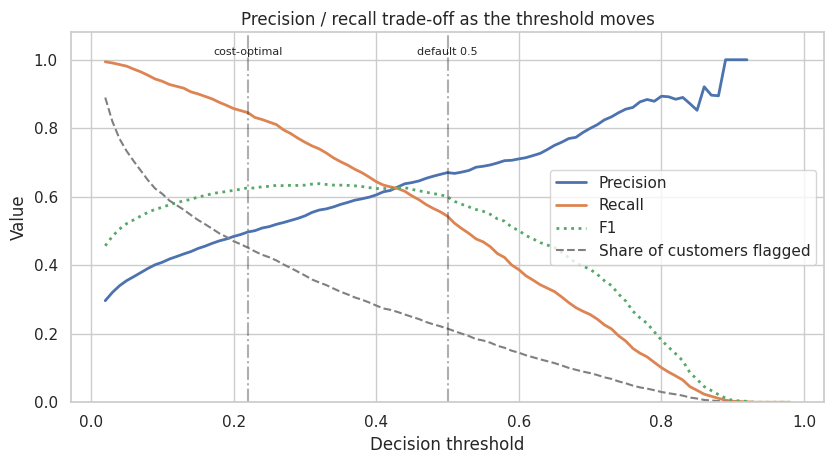

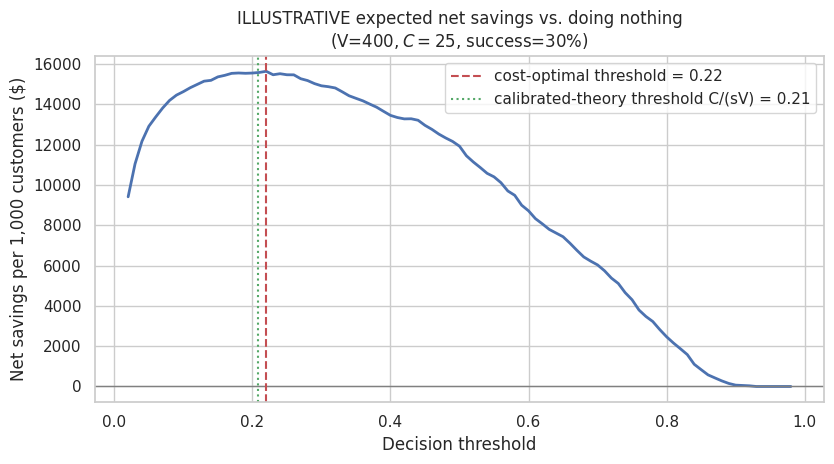

In [9]:
# ---- The ONE-TIME test-set evaluation. Model and threshold are already fixed (metadata.json). ----
res = ev.evaluate_final_model()
f, f5, d0, ci = res["final_at_chosen_threshold"], res["final_at_0.5"], res["dummy_at_0.5"], res["bootstrap_95ci"]
tab = pd.DataFrame({"final @ chosen threshold": f, "final @ 0.50": f5, "dummy baseline @ 0.50": d0}).T[["accuracy", "precision", "recall", "f1", "flagged_fraction", "roc_auc", "average_precision", "brier", "tp", "fp", "tn", "fn"]]
display(tab.round(3))
print("\n95% bootstrap CIs (final model, chosen threshold):")
for k, (lo, hi) in ci.items(): print(f"  {k:22s} {f.get(k, float('nan')):9.3f}   [{lo:.3f}, {hi:.3f}]" if k in f else f"  {k:22s} [{lo:,.0f}, {hi:,.0f}]")
print("\nOut-of-fold (dev) PR-AUC:", round(res["oof_at_chosen_threshold"]["average_precision"], 3), "| test PR-AUC:", round(f["average_precision"], 3))

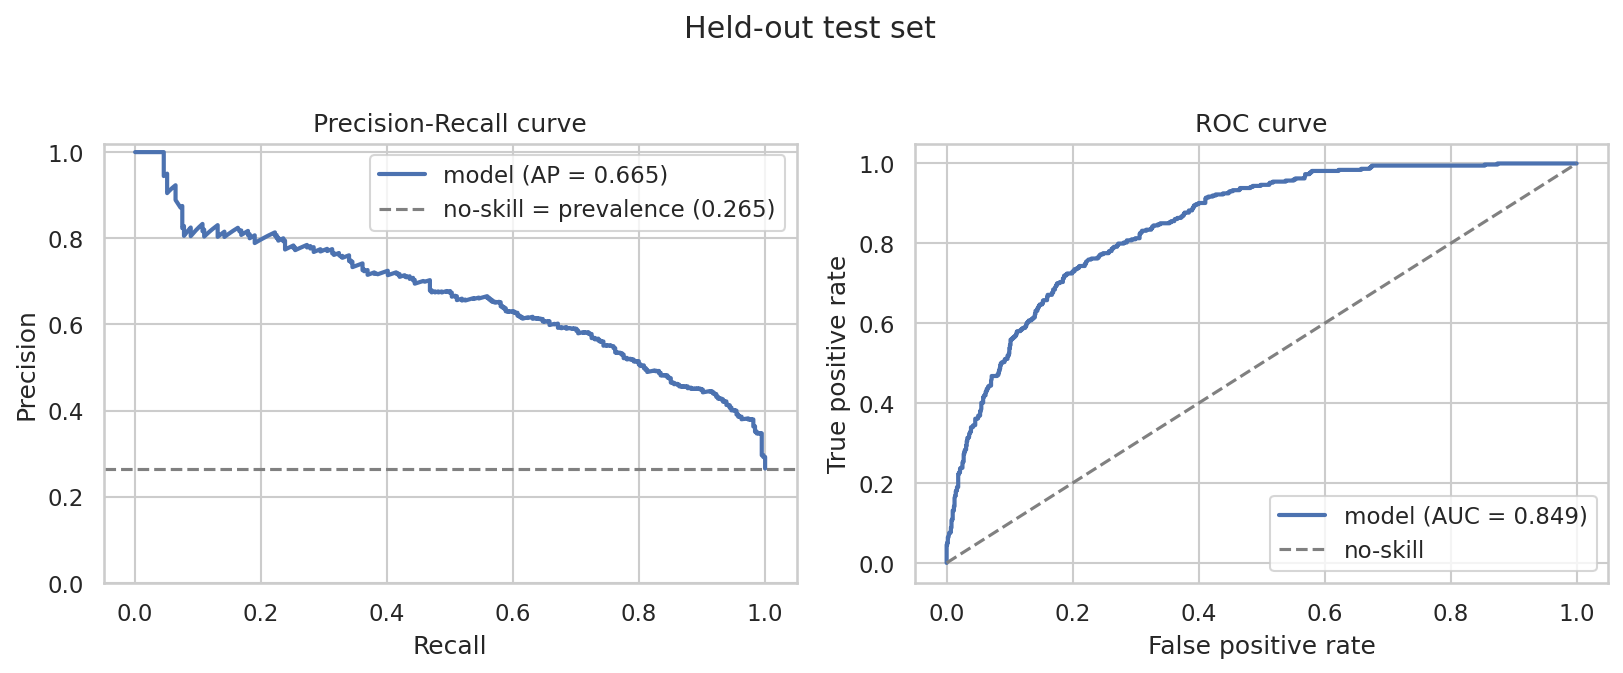

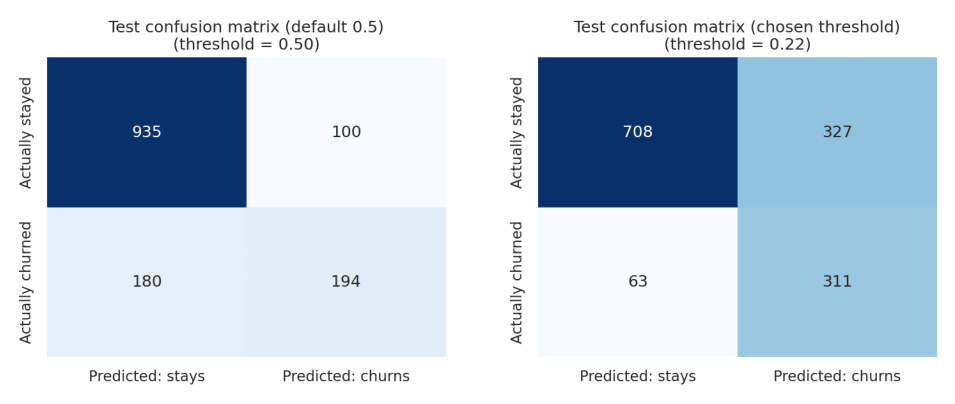

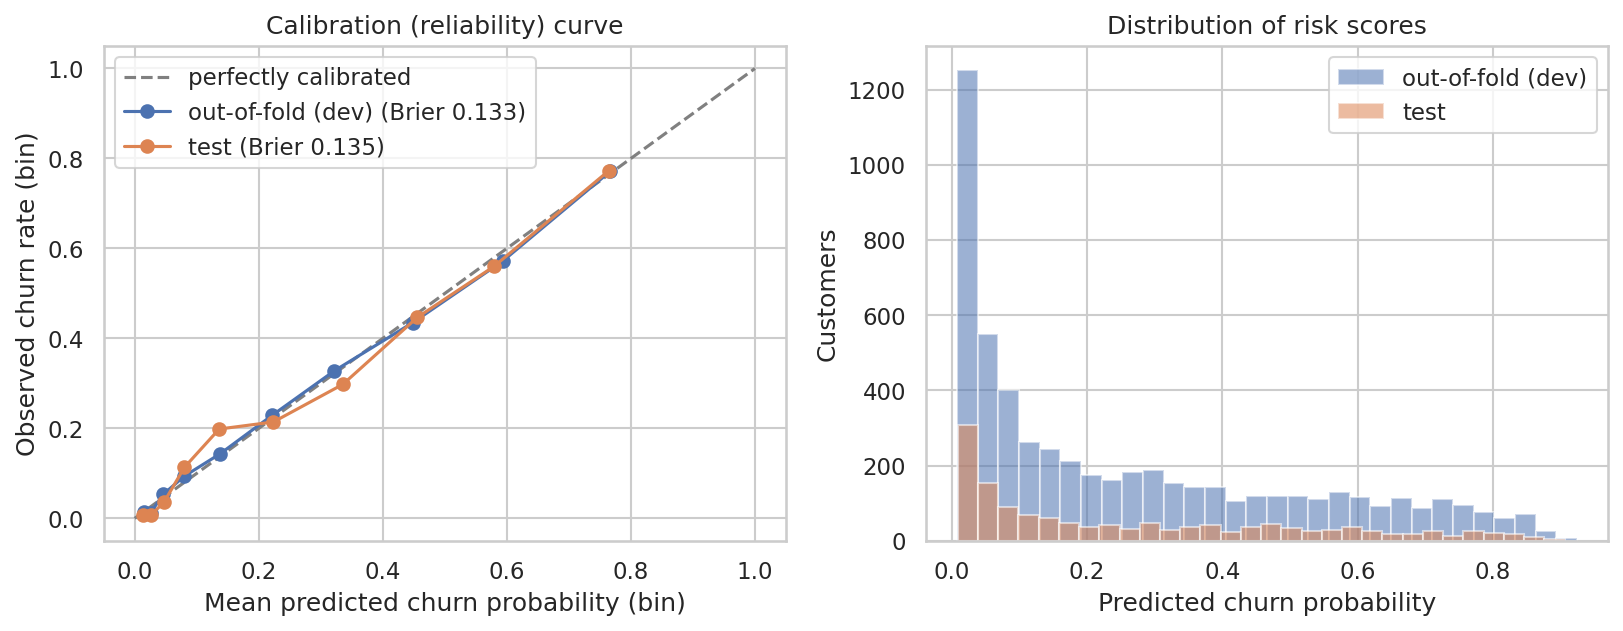

In [10]:
from IPython.display import Image, display as show_img
show_img(Image(str(config.FIGURES_DIR / "test_pr_roc_curves.png")))
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, name in zip(axes, ["test_confusion_matrix_default.png", "test_confusion_matrix_chosen.png"]):
    ax.imshow(plt.imread(config.FIGURES_DIR / name)); ax.axis("off")
plt.tight_layout(); plt.show()
show_img(Image(str(config.FIGURES_DIR / "calibration_curve.png")))

**Reading the test results.**
* **Ranking quality is solid but not spectacular:** ROC-AUC 0.849 (95% CI 0.827-0.870), PR-AUC 0.665 (0.612-0.713) against a no-skill 0.265. These match the cross-validation estimates (0.85 / 0.67), which is the check we want: no sign that selection or tuning overfitted the development data.
* **Threshold effect:** at the pre-chosen 0.22 threshold the model flags ~45% of customers, finds 83% of churners (recall) with 49% precision. At 0.5 it flags 21%, finds 52% with 66% precision. Neither is "better" in absolute terms - it depends on costs.
* **The honest ceiling:** roughly half of the customers we flag will not churn. That is inherent in this data (ROC-AUC 0.85, not 0.99): churn depends on things not in the dataset (competitor offers, service problems, life events). Do not read the numbers as a failure; read them as a realistic limit of the available features.
* **Uncertainty:** with 1,409 test customers (374 churners) the 95% intervals are about +/-0.05 for PR-AUC and +/-0.04 for recall. Differences between models smaller than that cannot be distinguished.
* **Calibration holds up on test**, with a Brier score of 0.135 vs 0.195 for the baseline.

### Subgroup check and customer-level risk scores

In [11]:
from src.data_preprocessing import load_split, split_xy
test_df = load_split("test"); Xte, yte = split_xy(test_df)
pte = joblib.load(config.MODEL_PATH).predict_proba(Xte)[:, 1]
for col in config.SENSITIVE_COLUMNS: display(ev.subgroup_metrics(test_df, yte, pte, chosen_t, col).round(3))
scores = pd.read_csv(config.RISK_SCORES_PATH); display(scores.head(8).round(3)); print(scores.shape, "customer-level out-of-sample risk scores saved to", config.RISK_SCORES_PATH.name)

,gender,n,churn_rate,flagged_rate,precision,recall,mean_predicted_prob,roc_auc
0,Female,687,0.281,0.453,0.505,0.813,0.266,0.845
1,Male,722,0.251,0.453,0.471,0.851,0.267,0.854


,SeniorCitizen,n,churn_rate,flagged_rate,precision,recall,mean_predicted_prob,roc_auc
0,No,1187,0.233,0.400,0.459,0.790,0.239,0.850
1,Yes,222,0.441,0.734,0.571,0.949,0.413,0.785


,customerID,churn_probability,score_source,actual_churn,flagged_at_threshold,risk_rank_percentile
0,7216-EWTRS,0.924,out-of-fold (development set),1,True,1.000
1,5419-JPRRN,0.921,out-of-fold (development set),1,True,1.000
2,9300-AGZNL,0.911,out-of-fold (development set),1,True,1.000
3,5178-LMXOP,0.905,final model (held-out test set),1,True,1.000
4,0107-YHINA,0.904,out-of-fold (development set),1,True,0.999
5,9497-QCMMS,0.900,out-of-fold (development set),1,True,0.999
6,5192-EBGOV,0.899,out-of-fold (development set),1,True,0.999
7,8149-RSOUN,0.898,out-of-fold (development set),1,True,0.999


(7043, 6) customer-level out-of-sample risk scores saved to customer_risk_scores.csv


**Reading it.** Gender groups get near-identical flag rates (45%), with small recall/precision differences consistent with different base churn rates (28% vs 25%) and sampling noise. Senior citizens are flagged far more often (73%) because they genuinely churn more in this data (44% vs 23%), but the model ranks them less well (ROC-AUC 0.79 vs 0.85) and the group is small (222 customers). Whether it is acceptable to use age or gender to target offers is a *policy and legal* question this project cannot settle; a production system should review it explicitly.

`reports/customer_risk_scores.csv` holds an **out-of-sample** score for every customer: out-of-fold for the development set, final-model for the test set - so no customer is scored by a model that trained on them.

## What to remember / interview questions
* *"Why is accuracy misleading here?"* - 73.5% is achieved by predicting "stays" for everyone.
* *"Precision vs recall for churn?"* - Depends on relative costs; recall for cheap/effective actions, precision when actions are costly or capacity-limited.
* *"Does choosing a threshold improve ROC-AUC?"* - No; it only changes the operating point on the same ROC/PR curve.
* *"How would you pick a threshold?"* - Estimate costs/benefits (ideally from an A/B test), compute expected cost on validation data, respect capacity limits, and check sensitivity.
* *"Why does calibration matter?"* - Cost-based decisions multiply probabilities by money; miscalibrated probabilities give wrong expected costs.